# Tarea 2. Detección de grietas en pavimento
**Procesamiento de Imágenes, Universidad Diego Portales**

Integrantes: _______________________ · _______________________

Sigan los pasos del enunciado en orden. Completen las funciones marcadas con
`NotImplementedError` sin cambiar sus nombres ni sus firmas, y agreguen las celdas de código que
pida cada paso. Este cuaderno contiene solo el código y sus salidas: los resultados y su análisis
van en el informe en PDF.

## 0. Preparación

In [1]:
import os, subprocess

RUTA = "CrackForest-dataset"
if not os.path.isdir(RUTA):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/cuilimeng/CrackForest-dataset.git", RUTA],
                   check=True)
print("imágenes:", len([f for f in os.listdir(f"{RUTA}/image") if f.endswith(".jpg")]))
print("máscaras:", len([f for f in os.listdir(f"{RUTA}/groundTruth") if f.endswith(".mat")]))

imágenes: 155
máscaras: 118


In [2]:
import time
import cv2
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.precision", 3)
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 5.0.0 | NumPy 2.5.2


## 1. Utilidades entregadas

**No modifiquen estas celdas.** Toda función de segmentación recibe una imagen en grises `uint8`
y devuelve una máscara `uint8` con valores en `{0, 1}` (no 0-255) y el mismo tamaño.
`evaluar_por_imagen` verifica este contrato y se detiene con un error si una máscara no lo cumple.
Varias funciones de OpenCV (`Canny`, `floodFill`, `threshold` con máximo 255) producen 0/255:
conviertan antes de devolver.

In [3]:
def cargar_par(nombre, ruta=RUTA):
    """Devuelve (imagen en escala de grises, máscara binaria) para un nombre como '001'."""
    img = cv2.imread(f"{ruta}/image/{nombre}.jpg", cv2.IMREAD_GRAYSCALE)
    mat = sio.loadmat(f"{ruta}/groundTruth/{nombre}.mat")
    seg = mat["groundTruth"][0, 0]["Segmentation"]   # 1 = fondo, 2 = grieta
    return img, (seg == 2).astype(np.uint8)


# La carpeta image/ tiene 155 archivos, pero solo 118 tienen máscara:
# los identificadores se construyen desde groundTruth/.
IDS = sorted(f[:-4] for f in os.listdir(f"{RUTA}/groundTruth") if f.endswith(".mat"))
print(f"{len(IDS)} pares imagen/máscara:", IDS[:5], "...", IDS[-3:])

118 pares imagen/máscara: ['001', '002', '003', '004', '005'] ... ['116', '117', '118']


In [4]:
def mostrar(imagenes, titulos=None, cols=4, escala=3.2, cmap="gray"):
    """Grilla de imágenes en escala de grises, binarias o RGB."""
    n = len(imagenes)
    filas = int(np.ceil(n / cols))
    fig, ax = plt.subplots(filas, cols, figsize=(escala * cols, escala * filas * 0.72))
    ax = np.atleast_1d(ax).ravel()
    for i, a in enumerate(ax):
        if i < n:
            im = imagenes[i]
            if im.ndim == 3:
                a.imshow(im)
            else:
                a.imshow(im, cmap=cmap, vmin=0, vmax=1 if im.max() <= 1 else 255)
            if titulos is not None:
                a.set_title(titulos[i], fontsize=9)
        a.axis("off")
    plt.tight_layout()
    plt.show()


def superponer(img, pred, gt):
    """Imagen RGB con la comparación: verde = acierto, rojo = falso positivo, azul = falso negativo."""
    p, g = pred.astype(bool), gt.astype(bool)
    out = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    out[p & g] = (0, 220, 0)
    out[p & ~g] = (230, 0, 0)
    out[~p & g] = (0, 90, 255)
    return out

In [5]:
def metricas(pred, gt):
    """Métricas a nivel de píxel entre una máscara predicha y la de referencia."""
    p, g = pred.astype(bool), gt.astype(bool)
    tp = int((p & g).sum())
    fp = int((p & ~g).sum())
    fn = int((~p & g).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
    return {"IoU": iou, "P": precision, "R": recall, "F1": f1}


def metricas_con_tolerancia(pred, gt, tol=2):
    """Igual que metricas(), pero admite un desajuste de hasta `tol` píxeles.

    Se cuenta como acierto todo píxel predicho que caiga dentro de la máscara de
    referencia dilatada, y como detectado todo píxel de referencia que caiga dentro
    de la predicción dilatada.
    """
    # se normaliza a {0, 1}: con una máscara 0/255 el denominador p.sum() quedaría inflado
    p, g = pred.astype(bool).astype(np.uint8), gt.astype(bool).astype(np.uint8)
    ee = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * tol + 1, 2 * tol + 1))
    precision = (p & cv2.dilate(g, ee)).sum() / p.sum() if p.sum() else 0.0
    recall = (g & cv2.dilate(p, ee)).sum() / g.sum() if g.sum() else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"P_tol": precision, "R_tol": recall, "F1_tol": f1}

In [6]:
def evaluar_por_imagen(segmentador, ids=None, tol=2):
    """Aplica `segmentador(img) -> máscara binaria` a cada imagen y devuelve un
    DataFrame con una fila por imagen (índice = identificador)."""
    ids = IDS if ids is None else ids
    filas = {}
    for n in ids:
        img, gt = cargar_par(n)
        pred = segmentador(img)
        assert pred.dtype == np.uint8 and pred.shape == gt.shape and pred.max() <= 1,             f"imagen {n}: la máscara debe ser uint8, del tamaño de la imagen y con valores {{0, 1}}"
        filas[n] = {**metricas(pred, gt), **metricas_con_tolerancia(pred, gt, tol)}
    return pd.DataFrame(filas).T


def evaluar_conjunto(segmentador, ids=None, tol=2):
    """Promedio sobre el conjunto de todas las métricas de evaluar_por_imagen()."""
    return evaluar_por_imagen(segmentador, ids, tol).mean().to_dict()


def tabla(resultados):
    """Convierte un dict {nombre: métricas} en un DataFrame con las columnas del informe."""
    df = pd.DataFrame(resultados).T
    return df[["IoU", "P", "R", "F1", "F1_tol"]]

In [7]:
FILTROS = {
    "sin filtro":          lambda x: x,
    "promediador 5×5":     lambda x: cv2.blur(x, (5, 5)),
    "gaussiano 5×5":       lambda x: cv2.GaussianBlur(x, (5, 5), 0),
    "mediana 5×5":         lambda x: cv2.medianBlur(x, 5),
    "mediana 9×9":         lambda x: cv2.medianBlur(x, 9),
    "bilateral (9,50,50)": lambda x: cv2.bilateralFilter(x, 9, 50, 50),
}

## Parte 1. Filtrado
### Paso 1. Relación contraste-ruido

In [8]:
def contraste_grieta_fondo(img, mascara):
    """CNR = |media(grieta) - media(fondo)| / desviacion(fondo), en punto flotante."""
    x = np.asarray(img, dtype=np.float64)
    g = np.asarray(mascara, dtype=bool)

    if x.shape != g.shape:
        raise ValueError(f"img y mascara deben tener la misma forma. Recibido: {x.shape} y {g.shape}")

    if not np.any(g):
        raise ValueError("La mascara no contiene pixeles de grieta (True).")

    fondo = ~g
    if not np.any(fondo):
        raise ValueError("La mascara no contiene pixeles de fondo (False).")

    media_grieta = x[g].mean()
    pix_fondo = x[fondo]
    media_fondo = pix_fondo.mean()
    std_fondo = pix_fondo.std()

    if std_fondo == 0:
        raise ValueError("La desviacion estandar del fondo es 0; CNR indefinido.")

    cnr = np.abs(media_grieta - media_fondo) / std_fondo
    return float(cnr)

### Paso 2. Ruta C con filtro intercambiable

**Idea.** La grieta es un *valle* oscuro y angosto (3 a 5 px). El cierre con un elemento de
`k_bh` × `k_bh` rellena todo valle más angosto que el elemento con el nivel del asfalto que lo
rodea, así que `cierre(f) − f` (black-hat) vale casi cero en el asfalto y es alto solo sobre la
grieta. Como esa respuesta es casi toda cercana a cero, el umbral `media + k_sigma · desviación`
se queda con los valores atípicos de cada imagen. El filtro se recibe como argumento para poder
cambiar **solo** el suavizado y medir su efecto sobre la segmentación (Tabla 1); por la misma
razón no lleva post-proceso.

In [9]:
def segmentar_blackhat_filtro(img, filtro, k_bh=21, k_sigma=3.0):
    """filtro(img) -> black-hat elíptico k_bh x k_bh -> umbral media + k_sigma * desviación. Sin post-proceso."""
    filtrada = filtro(img)
    ee = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_bh, k_bh))
    respuesta = cv2.morphologyEx(filtrada, cv2.MORPH_BLACKHAT, ee)
    umbral = respuesta.mean() + k_sigma * respuesta.std()
    return (respuesta > umbral).astype(np.uint8)

### Paso 3. Tabla 1 y recorte ampliado

In [10]:
filas_tabla1 = {}
for nombre, f in FILTROS.items():
    cnr_valores = []
    std_fondo_valores = []

    for identificador in IDS:
        img, mascara = cargar_par(identificador)
        img_filtrada = f(img)
        x = np.asarray(img_filtrada, dtype=np.float64)
        g = np.asarray(mascara, dtype=bool)
        pix_fondo = x[~g]

        cnr_valores.append(contraste_grieta_fondo(img_filtrada, mascara))
        std_fondo_valores.append(pix_fondo.std())

    metricas_f1 = evaluar_conjunto(
        lambda x, f=f: segmentar_blackhat_filtro(x, f)
    )
    filas_tabla1[nombre] = {
        "CNR medio": np.mean(cnr_valores),
        "sigma del fondo": np.mean(std_fondo_valores),
        "F1 aguas abajo": metricas_f1["F1"],
    }

tabla1 = pd.DataFrame(filas_tabla1).T
tabla1

,CNR medio,sigma del fondo,F1 aguas abajo
sin filtro,1.821,13.643,0.294
promediador 5×5,2.294,8.331,0.446
gaussiano 5×5,2.337,9.278,0.424
mediana 5×5,2.163,8.310,0.411
mediana 9×9,1.601,7.179,0.356
"bilateral (9,50,50)",2.315,7.719,0.468


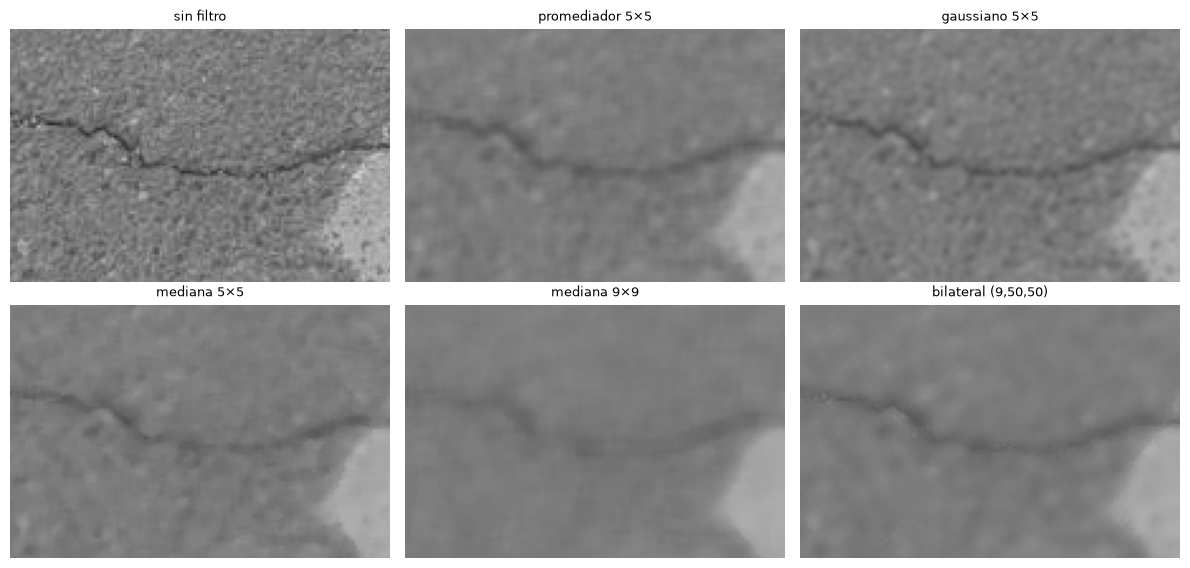

In [11]:
img_016, _ = cargar_par("016")
recortes = [f(img_016)[120:220, 180:330] for f in FILTROS.values()]
mostrar(
    recortes,
    titulos=list(FILTROS.keys()),
    cols=3,
    escala=4.0,
)

## Parte 2. Tres rutas de segmentación
### Paso 4. Ruta A, Otsu

In [12]:
def segmentar_otsu(img, k_mediana=5):
    """Mediana k_mediana x k_mediana y umbral de Otsu inverso."""
    suave = cv2.medianBlur(img, k_mediana)
    _, mascara = cv2.threshold(
        suave,
        0,
        1,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU,
    )
    return mascara.astype(np.uint8)

### Paso 5. Ruta B, Canny, cierre y relleno

In [13]:
def segmentar_canny(img, k_blur=5, t1=50, t2=150, k_cierre=5):
    """Ruta B: suavizado gaussiano, Canny, cierre elíptico y relleno del interior.

    Canny marca los dos bordes de la grieta, no la grieta. El cierre sella el
    contorno y el relleno por inundación desde una esquina, negado, recupera las
    regiones que quedaron encerradas.
    """
    suave = cv2.GaussianBlur(img, (k_blur, k_blur), 0)
    bordes = cv2.Canny(suave, t1, t2)
    ee = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (k_cierre, k_cierre),
    )
    contorno = cv2.morphologyEx(bordes, cv2.MORPH_CLOSE, ee)

    # --- Entregado: relleno del interior (no modificar) ---
    inundado = contorno.copy()
    h, w = contorno.shape
    cv2.floodFill(inundado, np.zeros((h + 2, w + 2), np.uint8), (0, 0), 255)
    interior = cv2.bitwise_not(inundado)
    return ((contorno > 0) | (interior > 0)).astype(np.uint8)

### Paso 6. Ruta C, black-hat

In [14]:
def segmentar_blackhat(img, k_mediana=5, k_bh=21, k_sigma=3.0):
    """segmentar_blackhat_filtro con mediana k_mediana x k_mediana."""
    return segmentar_blackhat_filtro(
        img,
        lambda x: cv2.medianBlur(x, k_mediana),
        k_bh=k_bh,
        k_sigma=k_sigma,
    )

### Paso 7. Tabla 2, fracción marcada y figura

In [15]:
RUTAS = {
    "A · Otsu": segmentar_otsu,
    "B · Canny": segmentar_canny,
    "C · Black-hat": segmentar_blackhat,
}

resultados_rutas = {
    nombre: evaluar_conjunto(ruta)
    for nombre, ruta in RUTAS.items()
}

tabla2 = tabla(resultados_rutas).rename(columns={"F1_tol": "F1 (tol = 2)"})
tabla2

,IoU,P,R,F1,F1 (tol = 2)
A · Otsu,0.039,0.039,0.912,0.073,0.138
B · Canny,0.122,0.206,0.490,0.202,0.333
C · Black-hat,0.273,0.444,0.410,0.411,0.630


In [16]:
fracciones_marcadas = {}
fracciones_reales = []

for identificador in IDS:
    img, gt = cargar_par(identificador)
    fracciones_reales.append(gt.mean())
    for nombre, ruta in RUTAS.items():
        fracciones_marcadas.setdefault(nombre, []).append(ruta(img).mean())

tabla2["Fracción marcada"] = [
    np.mean(fracciones_marcadas[nombre])
    for nombre in tabla2.index
]
fraccion_real = np.mean(fracciones_reales)

print(f"Fracción real de grieta: {fraccion_real:.4f}")
tabla2

Fracción real de grieta: 0.0162


,IoU,P,R,F1,F1 (tol = 2),Fracción marcada
A · Otsu,0.039,0.039,0.912,0.073,0.138,0.414
B · Canny,0.122,0.206,0.490,0.202,0.333,0.156
C · Black-hat,0.273,0.444,0.410,0.411,0.630,0.013


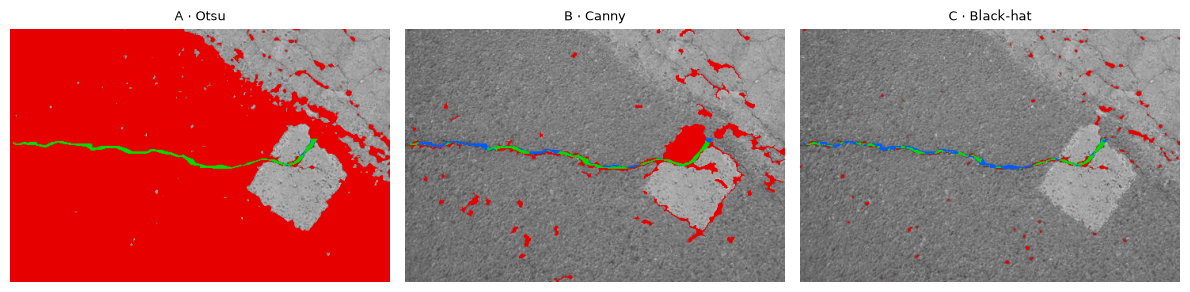

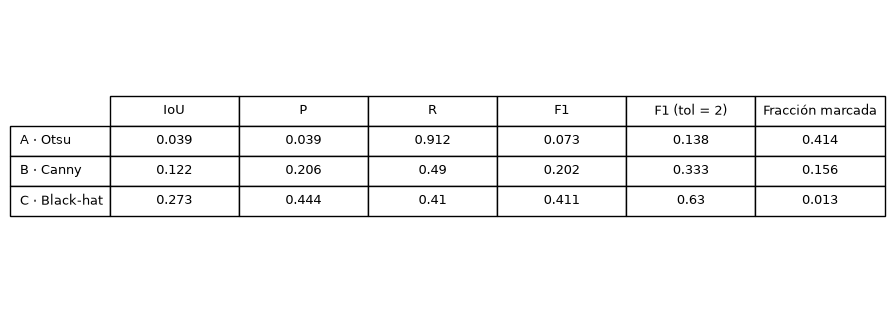

In [17]:
img_016, gt_016 = cargar_par("016")
pred_otsu_016 = segmentar_otsu(img_016)
pred_canny_016 = segmentar_canny(img_016)
pred_blackhat_016 = segmentar_blackhat(img_016)

superposiciones = [
    superponer(img_016, pred_otsu_016, gt_016),
    superponer(img_016, pred_canny_016, gt_016),
    superponer(img_016, pred_blackhat_016, gt_016),
]

mostrar(
    superposiciones,
    titulos=list(RUTAS.keys()),
    cols=3,
    escala=4.0,
)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axis("off")
tabla_grafica = ax.table(
    cellText=np.round(tabla2.values, 3),
    rowLabels=tabla2.index,
    colLabels=tabla2.columns,
    loc="center",
    cellLoc="center",
)
tabla_grafica.auto_set_font_size(False)
tabla_grafica.set_fontsize(9)
tabla_grafica.scale(1, 1.8)
plt.savefig("tabla2.png", dpi=200, bbox_inches="tight")
plt.show()

## Parte 3. Post-proceso morfológico
### Paso 8. `postprocesar`

In [18]:
def postprocesar(mascara, k_cierre=0, area_min=0, orden="cierre-area"):
    """Cierre morfológico y eliminación de componentes pequeñas.

    - Cierre con elemento elíptico de tamaño k_cierre.
    - Eliminación de componentes de área menor a area_min, usando
      cv2.connectedComponentsWithStats con conectividad 8.
    - orden = "cierre-area" o "area-cierre" fija qué etapa se aplica primero.

    k_cierre <= 1 o area_min <= 0 desactivan la etapa correspondiente.
    """
    def cierre(b):
        if k_cierre <= 1:
            return b
        ee = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (k_cierre, k_cierre),
        )
        return cv2.morphologyEx(b, cv2.MORPH_CLOSE, ee)

    # --- Entregado: filtro de área (no modificar) ---
    def area(b):
        if area_min <= 0:
            return b
        _, etiquetas, stats, _ = cv2.connectedComponentsWithStats(b, connectivity=8)
        conservar = np.where(stats[1:, cv2.CC_STAT_AREA] >= area_min)[0] + 1
        return np.isin(etiquetas, conservar).astype(np.uint8)

    if orden == "cierre-area":
        resultado = area(cierre(mascara))
    elif orden == "area-cierre":
        resultado = cierre(area(mascara))
    else:
        raise ValueError(
            "orden debe ser 'cierre-area' o 'area-cierre'"
        )

    return resultado.astype(np.uint8)

### Paso 9. Tabla 3 y figura

In [19]:
configuraciones_tabla3 = {
    "A · Otsu · crudo": segmentar_otsu,
    "A · Otsu · + cierre(9)": lambda x: postprocesar(
        segmentar_otsu(x), k_cierre=9
    ),
    "C · Black-hat · crudo": segmentar_blackhat,
    "C · Black-hat · + cierre(9)": lambda x: postprocesar(
        segmentar_blackhat(x), k_cierre=9
    ),
    "C · Black-hat · + área(50)": lambda x: postprocesar(
        segmentar_blackhat(x), area_min=50
    ),
    "C · Black-hat · cierre(9) → área(50)": lambda x: postprocesar(
        segmentar_blackhat(x), k_cierre=9, area_min=50,
        orden="cierre-area"
    ),
    "C · Black-hat · área(50) → cierre(9)": lambda x: postprocesar(
        segmentar_blackhat(x), k_cierre=9, area_min=50,
        orden="area-cierre"
    ),
}

resultados_tabla3 = {
    nombre: evaluar_conjunto(segmentador)
    for nombre, segmentador in configuraciones_tabla3.items()
}

tabla3 = tabla(resultados_tabla3).rename(
    columns={"F1_tol": "F1 (tol = 2)"}
)
tabla3

,IoU,P,R,F1,F1 (tol = 2)
A · Otsu · crudo,0.039,0.039,0.912,0.073,0.138
A · Otsu · + cierre(9),0.029,0.029,0.957,0.056,0.112
C · Black-hat · crudo,0.273,0.444,0.410,0.411,0.630
C · Black-hat · + cierre(9),0.292,0.441,0.459,0.433,0.636
C · Black-hat · + área(50),0.229,0.546,0.286,0.347,0.484
C · Black-hat · cierre(9) → área(50),0.292,0.531,0.394,0.427,0.595
C · Black-hat · área(50) → cierre(9),0.237,0.539,0.303,0.358,0.484


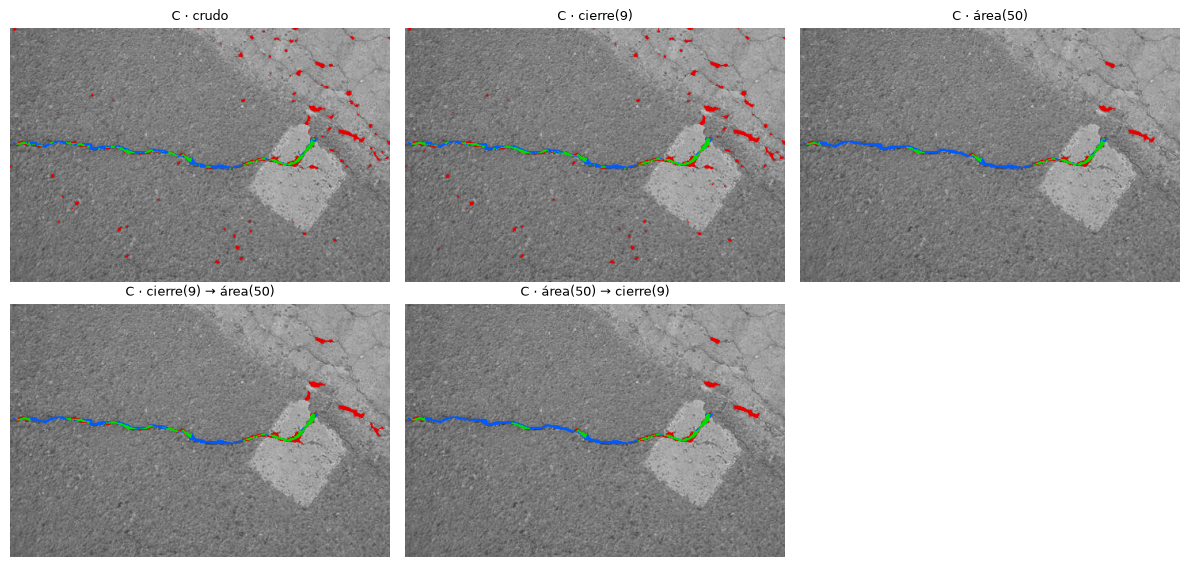

In [20]:
img_016, gt_016 = cargar_par("016")
configuraciones_c = {
    "C · crudo": segmentar_blackhat(img_016),
    "C · cierre(9)": postprocesar(
        segmentar_blackhat(img_016), k_cierre=9
    ),
    "C · área(50)": postprocesar(
        segmentar_blackhat(img_016), area_min=50
    ),
    "C · cierre(9) → área(50)": postprocesar(
        segmentar_blackhat(img_016),
        k_cierre=9,
        area_min=50,
        orden="cierre-area",
    ),
    "C · área(50) → cierre(9)": postprocesar(
        segmentar_blackhat(img_016),
        k_cierre=9,
        area_min=50,
        orden="area-cierre",
    ),
}

superposiciones_c = [
    superponer(img_016, pred, gt_016)
    for pred in configuraciones_c.values()
]
mostrar(
    superposiciones_c,
    titulos=list(configuraciones_c.keys()),
    cols=3,
    escala=4.0,
)

## Parte 4. Pipeline final
### Paso 10. `pipeline_final`, Tabla 4 y gráfico

In [21]:
def pipeline_final(img):
    """Mejor filtro (Tabla 1) -> black-hat -> postprocesar con cierre(9) y área(50), en ese orden."""
    nombre_filtro = tabla1["F1 aguas abajo"].idxmax()
    filtro = FILTROS[nombre_filtro]
    mascara = segmentar_blackhat_filtro(img, filtro)
    return postprocesar(
        mascara,
        k_cierre=9,
        area_min=50,
        orden="cierre-area",
    )

In [22]:
rutas_tabla4 = {
    "A · Otsu": segmentar_otsu,
    "B · Canny": segmentar_canny,
    "C · Black-hat": segmentar_blackhat,
    "Pipeline final": pipeline_final,
}

resultados_tabla4 = {
    nombre: evaluar_conjunto(segmentador)
    for nombre, segmentador in rutas_tabla4.items()
}

tabla4 = tabla(resultados_tabla4).rename(
    columns={"F1_tol": "F1 (tol = 2)"}
)
tabla4

,IoU,P,R,F1,F1 (tol = 2)
A · Otsu,0.039,0.039,0.912,0.073,0.138
B · Canny,0.122,0.206,0.490,0.202,0.333
C · Black-hat,0.273,0.444,0.410,0.411,0.630
Pipeline final,0.346,0.519,0.513,0.492,0.682


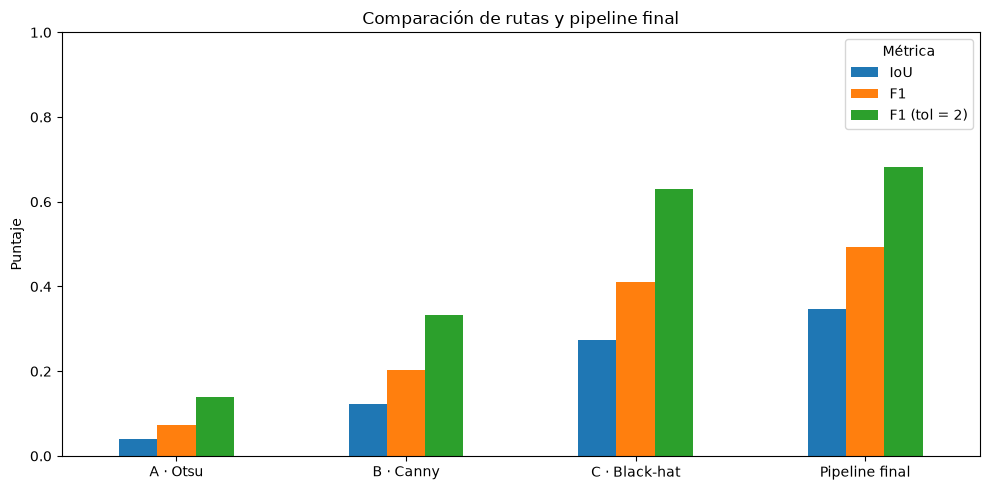

In [23]:
metricas_grafico = ["IoU", "F1", "F1 (tol = 2)"]
tabla4[metricas_grafico].plot(
    kind="bar",
    figsize=(10, 5),
    ylabel="Puntaje",
    title="Comparación de rutas y pipeline final",
    ylim=(0, 1),
    rot=0,
)
plt.legend(title="Métrica")
plt.tight_layout()
plt.show()

### Paso 11. Peores y mejores casos

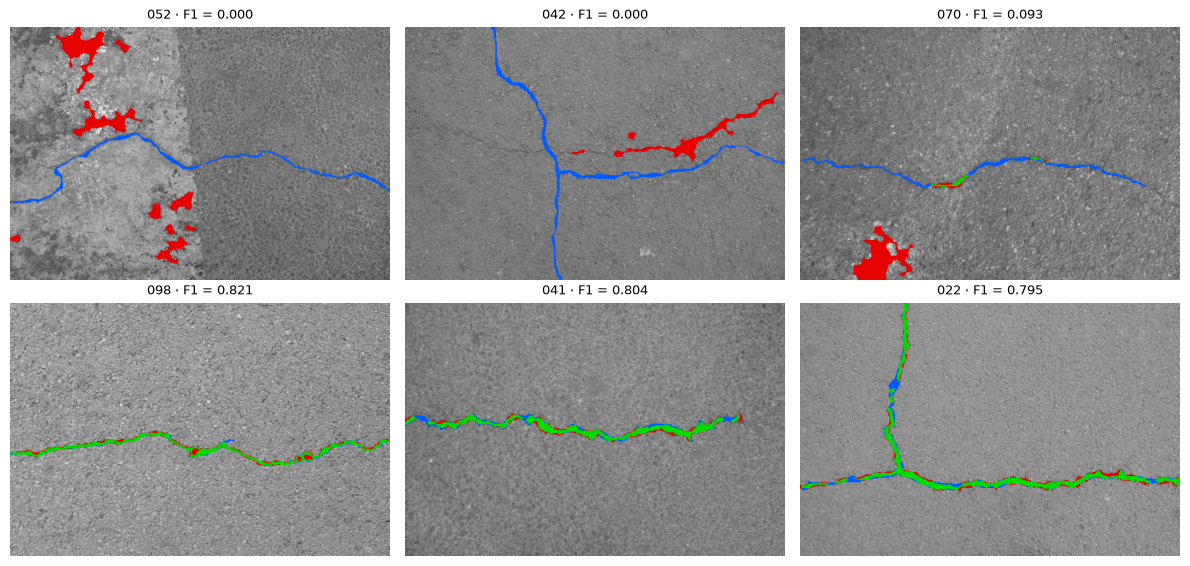

In [24]:
resultados_pipeline = evaluar_por_imagen(pipeline_final).sort_values("F1")
peores = resultados_pipeline.head(3)
mejores = resultados_pipeline.tail(3).sort_values("F1", ascending=False)

casos_extremos = pd.concat([
    peores.assign(grupo="Peores"),
    mejores.assign(grupo="Mejores"),
])
casos_extremos[["grupo", "F1", "IoU", "P", "R", "F1_tol"]]

ids_extremos = list(peores.index) + list(mejores.index)
superposiciones_extremos = []
titulos_extremos = []

for identificador in ids_extremos:
    img, gt = cargar_par(identificador)
    pred = pipeline_final(img)
    f1 = resultados_pipeline.loc[identificador, "F1"]
    superposiciones_extremos.append(superponer(img, pred, gt))
    titulos_extremos.append(f"{identificador} · F1 = {f1:.3f}")

mostrar(
    superposiciones_extremos,
    titulos=titulos_extremos,
    cols=3,
    escala=4.0,
)